# Experiment 4: Hill climbing
**Aim.** To implement hill climbing as a local search, observe its failure on local optima, plateaus and ridges,
and measure the improvement from random restarts.

## Theory (summary)
* Local search keeps one state, uses constant memory and is not complete.
* Failure modes: **local maximum**, **plateau** (a shoulder can be escaped with sideways moves; a flat maximum cannot) and **ridge**.
* With $k$ independent restarts: $P(\text{success}) = 1 - (1-p)^k$.

In [1]:
%matplotlib inline
import os
import numpy as np
import matplotlib.pyplot as plt
os.makedirs('figs', exist_ok=True)
plt.rcParams['figure.dpi'] = 110

## Example 1: Seeing the landscape

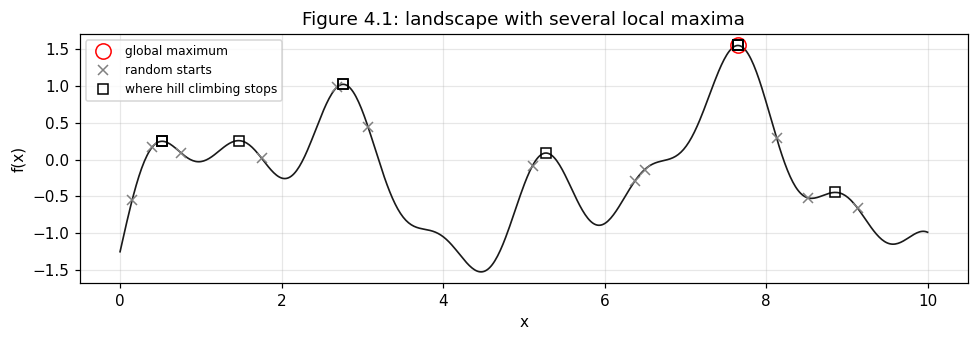

4 of 12 1-D runs reached the global maximum at x = 7.65


In [2]:
xs = np.linspace(0, 10, 600)
fx = np.sin(xs) + 0.6*np.sin(2.7*xs) + 0.35*np.sin(5.1*xs) - 0.05*(xs-5)**2

def hill_climb_1d(i):
    # steepest ascent on the sampled grid: move to the better neighbour until stuck
    while True:
        nb = [j for j in (i-1, i+1) if 0 <= j < len(xs)]
        best = max(nb, key=lambda j: fx[j])
        if fx[best] <= fx[i]:
            return i
        i = best

rng = np.random.default_rng(0)
starts = rng.integers(0, len(xs), 12)
ends = [hill_climb_1d(s) for s in starts]

plt.figure(figsize=(9, 3.2))
plt.plot(xs, fx, lw=1.1, color='0.1')
plt.plot(xs[np.argmax(fx)], fx.max(), 'o', ms=10, mfc='none', mec='r', label='global maximum')
plt.plot(xs[starts], fx[starts], 'x', color='0.5', label='random starts')
plt.plot(xs[ends], fx[ends], 's', mfc='none', mec='k', label='where hill climbing stops')
plt.xlabel('x'); plt.ylabel('f(x)'); plt.legend(fontsize=8)
plt.title('Figure 4.1: landscape with several local maxima')
plt.grid(alpha=0.3); plt.tight_layout(); plt.savefig('figs/fig4_1_landscape.png'); plt.show()

found = sum(e == np.argmax(fx) for e in ends)
print(f'{found} of {len(starts)} 1-D runs reached the global maximum at x = {xs[np.argmax(fx)]:.2f}')

## Example 2: Hill climbing on eight queens

In [3]:
import random

def conflicts(board):                      # from Experiment 2
    n = len(board); bad = 0
    for i in range(n):
        for j in range(i+1, n):
            if board[i] == board[j] or abs(board[i]-board[j]) == abs(i-j):
                bad += 1
    return bad

def hill_climb(n=8, seed=0):
    '''Steepest ascent. Returns True if a conflict-free board is reached.'''
    r = random.Random(seed)
    board = [r.randrange(n) for _ in range(n)]     # a complete, random board
    while True:
        current = conflicts(board)
        if current == 0:
            return True                             # solved
        best, move = current, None
        for c in range(n):                          # try every single-queen move
            old = board[c]
            for row in range(n):
                if row == old: continue
                board[c] = row
                v = conflicts(board)
                if v < best:
                    best, move = v, (c, row)
            board[c] = old
        if move is None:
            return False                            # local minimum: stuck
        board[move[0]] = move[1]

## Example 3: Random restarts

In [4]:
def hill_climb_restarts(n=8, restarts=10, seed=0):
    for k in range(restarts):
        if hill_climb(n, seed=seed*1000 + k):
            return True
    return False

trials = 200
plain = sum(hill_climb(8, seed=s) for s in range(trials)) / trials
print(f'plain hill climbing: {100*plain:.1f}% of {trials} random starts')

ks = (1, 2, 5, 10, 20)
measured = []
for k in ks:
    ok = sum(hill_climb_restarts(8, k, seed=1000+s) for s in range(trials)) / trials
    measured.append(ok)
    print(f'{k:>3} restarts: {100*ok:5.1f}%')

plain hill climbing: 12.5% of 200 random starts


  1 restarts:  14.5%


  2 restarts:  25.5%


  5 restarts:  56.0%


 10 restarts:  78.0%


 20 restarts:  97.5%


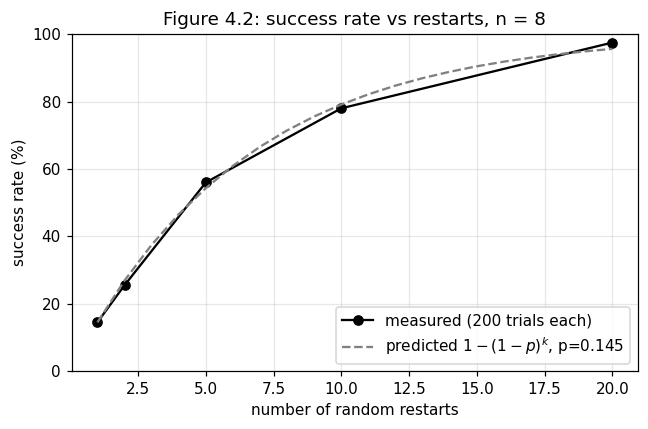

Restarts   Success  Predicted
       1     14.5%      14.5%
       2     25.5%      26.9%
       5     56.0%      54.3%
      10     78.0%      79.1%
      20     97.5%      95.6%
restarts needed for 99% success (independence assumed): 30
sampling std. error of the plain rate with 200 trials: +/- 2.3 percentage points


In [5]:
p = measured[0]          # single-run success rate estimated from the k=1 row
pred = [1 - (1-p)**k for k in ks]
kk = np.arange(1, 21)

plt.figure(figsize=(6, 4))
plt.plot(ks, 100*np.array(measured), 'ko-', label=f'measured ({trials} trials each)')
plt.plot(kk, 100*(1 - (1-p)**kk), '--', color='0.5', label=f'predicted $1-(1-p)^k$, p={p:.3f}')
plt.xlabel('number of random restarts'); plt.ylabel('success rate (%)'); plt.ylim(0, 100)
plt.legend(); plt.grid(alpha=0.3)
plt.title('Figure 4.2: success rate vs restarts, n = 8')
plt.tight_layout(); plt.savefig('figs/fig4_2_restarts.png'); plt.show()

print(f"{'Restarts':>8} {'Success':>9} {'Predicted':>10}")
for k, m, pr in zip(ks, measured, pred):
    print(f'{k:>8} {100*m:>8.1f}% {100*pr:>9.1f}%')

k99 = int(np.ceil(np.log(0.01) / np.log(1 - p)))
print(f'restarts needed for 99% success (independence assumed): {k99}')
se = np.sqrt(plain*(1-plain)/trials)
print(f'sampling std. error of the plain rate with {trials} trials: +/- {100*se:.1f} percentage points')

## Observations to record
The tables above give the plain success rate over 200 starts, the success rate at each restart count and the
prediction $1-(1-p)^k$. The number of trials is stated next to every percentage.

## Discussion
* **Expected:** plain hill climbing solves roughly 1 in 6 to 1 in 7 boards. Restarts push this towards 100 % following $1-(1-p)^k$.
* **Observed:** the measured curve tracks the prediction to within the sampling error (a few percentage points at 200 trials).
  This confirms that the restarts behave as independent trials.
* In 1-D, most starts stop at a local maximum. Hill climbing never learns that a higher peak exists.

## Viva questions (short answers)
1. Hill climbing gets stuck at a local maximum, on a plateau or on a ridge. Sideways moves can fix a *shoulder* plateau, but not a flat maximum or a true local maximum.
2. It stores only the current state; backtracking stores the recursion stack and partial assignment.
3. $k = \lceil \ln 0.01 / \ln(1-p) \rceil$ (printed above). This assumes the restarts are independent.
4. Use hill climbing (min-conflicts) for $n = 1000$. Repairing a complete board scales almost linearly, while backtracking is exponential.
5. No. With 200 trials the standard error is about ±2.5 points, so 12.5 % and 15.5 % are consistent.